# EDA del grafo de Internet

In [2]:
import networkx as nx

G = nx.read_gml('../fetch/topology-202504-month-PARTIAL.gml')

In [3]:
# Chequeo básico
print(f"El grafo cargado de Internet es conexo: {nx.is_connected(G)}")

El grafo cargado de Internet es conexo: True


In [32]:
# Algunos shortest paths

nx.shortest_path(G, source='1797', target='3356')

['1797', '6057', '3356']

In [48]:
import random
import math
import statistics as stat

def random_sample_file(filename, k):
    with open(filename, 'r') as file:
        lines = file.readlines()
        # Ensure k is not larger than total lines
        sample_size = min(k, len(lines))
        return random.sample(lines, sample_size)

# Usage: get 10 random lines
sample = random_sample_file('../fetch/asns-202504-week1.txt', 10)
source = '1797'
lens = []
for s in sample:
    s = s.strip()
    target = s.lstrip('0')
    sp = nx.shortest_path(G, source=source, target=target)
    ln = len(sp)
    lens.append(ln)
    print(f"Shortest path from source={source} to={target} is {sp} with length {ln}")

#
print(f"Average length: {stat.mean(lens)}")
    
    


Average length: 4.434


Average length: 3.52
Median length: 3.0


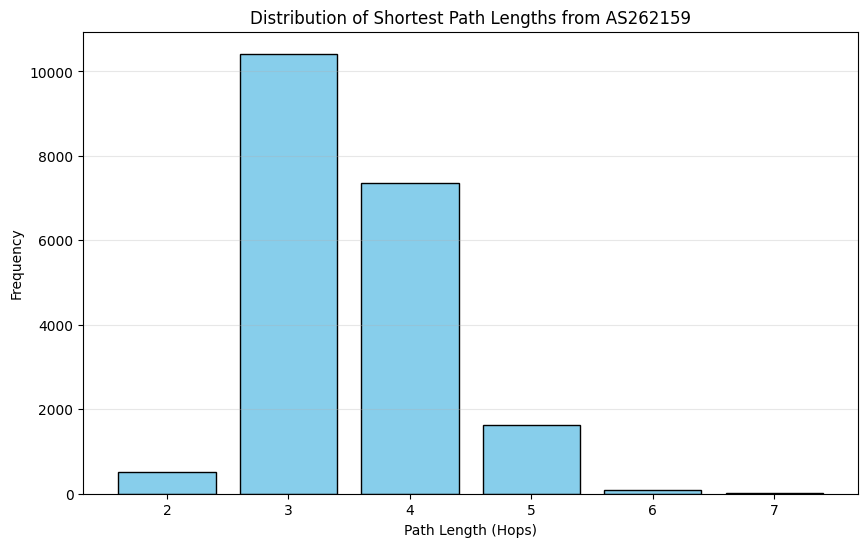

In [55]:
## Histograma

import random
import statistics as stat
import networkx as nx
import matplotlib.pyplot as plt
from collections import Counter

def get_random_sample(filename, k):
    """Memory-efficient way to sample lines from a large file."""
    with open(filename, 'r') as file:
        # Using list(file) is faster for medium files, 
        # but for massive files, consider reservoir sampling.
        lines = file.readlines()
        return random.sample(lines, min(k, len(lines)))

# Configuration
SOURCE_NODE = '262159'
SAMPLE_SIZE = 20000
FILE_PATH = '../fetch/asns-202504-week1.txt'

# 1. Get sample and calculate lengths
sample = get_random_sample(FILE_PATH, SAMPLE_SIZE)
path_lengths = []

for line in sample:
    target = line.strip().lstrip('0')
    try:
        # nx.shortest_path_length is slightly faster than len(nx.shortest_path)
        length = nx.shortest_path_length(G, source=SOURCE_NODE, target=target)
        path_lengths.append(length)
    except nx.NetworkXNoPath:
        print(f"No path found for target: {target}")
    except nx.NodeNotFound:
        continue

# 2. Statistics
if path_lengths:
    print(f"Average length: {stat.mean(path_lengths):.2f}")
    print(f"Median length: {stat.median(path_lengths)}")

    # 3. Build the Histogram
    plt.figure(figsize=(10, 6))
    
    # Calculate bins based on the range of lengths
    bins = range(min(path_lengths), max(path_lengths) + 2)
    
    plt.hist(path_lengths, bins=bins, align='left', rwidth=0.8, color='skyblue', edgecolor='black')
    
    plt.title(f'Distribution of Shortest Path Lengths from AS{SOURCE_NODE}')
    plt.xlabel('Path Length (Hops)')
    plt.ylabel('Frequency')
    plt.xticks(bins[:-1])
    plt.grid(axis='y', alpha=0.3)
    
    plt.show()
else:
    print("No valid paths were found to sample.")